<a href="https://colab.research.google.com/github/singhnih680-ops/hr-employee-attrition-prediction/blob/main/Copy_of_HR_Attrition_Monday_Complete_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HR Employee Attrition Prediction
## Monday hands-on lab — complete beginner ML pipeline
**Course:** Introduction to AI and ML 25BBM2561 • **CLOs:** CO1, CO2, CO3 • **Suggested time:** 3 hours guided practice.

### Industry problem
A fictional HR team wants to identify employees who may resign within the next year so that managers can offer supportive conversations. This notebook creates fictional historical employee records automatically. No CSV download or real employee data is required. Features represent information available at the prediction date; the target records the following year's outcome.

### What can go on your resume
After completing and understanding this lab, you may write:
> Built an educational HR attrition classification pipeline in Python using synthetic data, Pandas EDA, train-only preprocessing, SMOTENC and Logistic Regression; evaluated accuracy, precision, recall and F1 on held-out records.

Add your actual results only after running the notebook. Do not claim deployment, real-client work or reduced attrition. Upload this notebook and an adapted README to a GitHub repository named `hr-attrition-ml-pipeline`.

### How to run
Upload this `.ipynb` at **https://colab.research.google.com/** using **File → Upload notebook**. Choose a standard CPU runtime. Run cells from top to bottom using each cell's play button. Wait for installation before continuing. Each code cell performs one learning step and has comments explaining its purpose.

### Pipeline
Generate and load → inspect → clean → define features → split → training-only EDA → impute → scale → SMOTENC → one-hot encode → train → evaluate → interpret → save.

**Class meaning:** 0 = stayed; 1 = resigned. We predict an outcome, not a person's intentions or the cause of resignation. SMOTE is an extension requested for this lab; it is not explicitly named in the uploaded syllabus.


## 1 Install the required libraries

**Purpose:** Make the notebook work in Colab. Installation messages are normal. **Expected output:** installation completes without an error.


In [ ]:
# Install known compatible versions to make classroom runs reproducible.
# %pip installs packages in the same Python environment as this notebook.
# If Colab asks for a restart, restart the session and run from this cell again.
%pip install -q scikit-learn==1.7.2 imbalanced-learn==0.14.0


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.4/9.4 MB 46.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 240.0/240.0 kB 17.4 MB/s eta 0:00:00


## 2 Import tools

**Purpose:** Import reusable tools rather than writing every operation ourselves. Pandas handles tables; NumPy handles numerical calculations; Matplotlib draws graphs.


In [ ]:
# Import table, numerical, chart and file-saving tools.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
# Import tools for separating data, preprocessing and evaluating predictions.
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
# SMOTENC is the SMOTE variant for mixed numerical and categorical inputs.
from imblearn.over_sampling import SMOTENC
# A fixed seed makes the generated data repeatable.
SEED = 42
print('Tools are ready. Positive class: 1 = resigned.')


Tools are ready. Positive class: 1 = resigned.


## 3 Automatically create the fictional dataset

**Purpose:** Generate 1,000 fictional historical employees. A hidden teaching formula creates the target with randomness, so the answer is not perfectly determined. We deliberately add missing values and duplicate rows for cleaning practice. **Expected output:** a CSV saved locally and row count 1,020.


In [ ]:
# Use a local random generator so the same seed produces the same records.
rng = np.random.default_rng(SEED)
n = 1000
# Create explanatory inputs; all represent information available before the outcome.
experience = rng.integers(0, 26, n)
salary = np.round(28000 + experience * 2300 + rng.normal(0, 11000, n)).clip(18000, 150000)
satisfaction = rng.integers(1, 6, n)
overtime = rng.integers(0, 36, n)
absences = rng.integers(0, 13, n)
department = rng.choice(['Sales', 'Finance', 'IT', 'Operations'], n)
work_mode = rng.choice(['Office', 'Hybrid', 'Remote'], n)
# A teaching formula creates a probability, not a real-world causal model.
log_odds = -2.2 + 0.6 * (3 - satisfaction) + 0.055 * (overtime - 15) + 0.08 * (absences - 5) - 0.000012 * (salary - 45000)
probability = 1 / (1 + np.exp(-log_odds))
# Random outcomes preserve uncertainty: similar employees can have different outcomes.
resigned = (rng.random(n) < probability).astype(int)
raw = pd.DataFrame({'EmployeeID': [f'E{i:04d}' for i in range(1, n+1)],
                    'Department': department, 'WorkMode': work_mode,
                    'ExperienceYears': experience, 'MonthlySalary': salary,
                    'SatisfactionScore': satisfaction, 'OvertimeHours': overtime,
                    'Absences': absences, 'Resigned': resigned})
# Insert missing values only into inputs, never into the target.
for column in ['MonthlySalary', 'SatisfactionScore', 'Department']:
    raw.loc[rng.choice(n, 35, replace=False), column] = np.nan
# Append 20 exact duplicates to demonstrate removal of repeated records.
raw = pd.concat([raw, raw.sample(20, random_state=SEED)], ignore_index=True)
raw.to_csv('hr_attrition_raw.csv', index=False)
print('Synthetic CSV created:', raw.shape, '\nNo real employee information is used.')


Synthetic CSV created: (1020, 9) 
No real employee information is used.


## 4 Load the automatically created CSV

**Purpose:** Practise the same loading command used for a normal CSV. **Expected output:** the first five rows.


In [ ]:
# Read the file created in the previous cell into a table called df.
df = pd.read_csv('hr_attrition_raw.csv')
# head displays a preview, not the complete dataset.
display(df.head())
print('Rows:', df.shape[0], '| Columns:', df.shape[1])


,EmployeeID,Department,WorkMode,ExperienceYears,MonthlySalary,SatisfactionScore,OvertimeHours,Absences,Resigned
0,E0001,Finance,Hybrid,2,48365.0,2.0,27,5,1
1,E0002,IT,Remote,20,75007.0,3.0,3,7,0
2,E0003,IT,Remote,17,73489.0,1.0,14,10,0
3,E0004,Finance,Office,11,52675.0,5.0,0,4,0
4,E0005,Sales,Hybrid,11,51426.0,4.0,16,10,0


Rows: 1020 | Columns: 9


### Data dictionary
| Column | Meaning | Role |
|---|---|---|
| EmployeeID | Fictional unique employee code | Identifier; excluded from model |
| Department | Sales, Finance, IT or Operations | Categorical input |
| WorkMode | Office, Hybrid or Remote | Categorical input |
| ExperienceYears | Years of experience | Numerical input |
| MonthlySalary | Monthly salary in INR | Numerical input |
| SatisfactionScore | Satisfaction from 1 to 5 | Ordinal input treated numerically for this introductory lab |
| OvertimeHours | Overtime in a snapshot month | Numerical input |
| Absences | Absence days in that snapshot month | Numerical input |
| Resigned | Left within the following year: 0 or 1 | Target |

The simplified use of satisfaction as a number assumes comparable spacing between scores. Production modelling would examine that assumption. Features must be available before the outcome.


## 5 Inspect quality

**Purpose:** Find data types, missing values and duplicates before choosing how to clean. Missing does not mean zero.


In [ ]:
# info displays types and counts of non-missing values.
df.info()
# Count missing values per column and repeated complete rows.
display(df.isna().sum().rename('Missing values').to_frame())
print('Exact duplicate rows:', df.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   EmployeeID         1020 non-null   object 
 1   Department         985 non-null    object 
 2   WorkMode           1020 non-null   object 
 3   ExperienceYears    1020 non-null   int64  
 4   MonthlySalary      985 non-null    float64
 5   SatisfactionScore  983 non-null    float64
 6   OvertimeHours      1020 non-null   int64  
 7   Absences           1020 non-null   int64  
 8   Resigned           1020 non-null   int64  
dtypes: float64(2), int64(4), object(3)
memory usage: 71.8+ KB


,Missing values
EmployeeID,0
Department,35
WorkMode,0
ExperienceYears,0
MonthlySalary,35
SatisfactionScore,37
OvertimeHours,0
Absences,0
Resigned,0


Exact duplicate rows: 20


## 6 Clean duplicate records and validate ranges

**Purpose:** Remove exact repeats before splitting so the same employee cannot leak into train and test sets. Do not calculate missing-value replacements yet: learn these from training data only.


In [ ]:
# Remove exact duplicates and create a separate cleaned table.
clean = df.drop_duplicates().reset_index(drop=True).copy()
# Stop if the target has missing values or an unexpected category.
assert clean['Resigned'].notna().all()
assert set(clean['Resigned'].unique()) <= {0, 1}
assert clean['EmployeeID'].is_unique
# Range checks detect impossible values; missing values are handled later.
assert clean['MonthlySalary'].dropna().between(18000, 150000).all()
assert clean['SatisfactionScore'].dropna().between(1, 5).all()
assert clean['ExperienceYears'].between(0, 25).all()
print('Rows before:', len(df), '| Rows after:', len(clean))
print('Missing inputs retained for training-only imputation.')


Rows before: 1020 | Rows after: 1000
Missing inputs retained for training-only imputation.


## 7 Select inputs and target

**Purpose:** Features are the information given to the model; the target is the answer it learns. Exclude EmployeeID and any information collected after resignation.


In [ ]:
# Define a deliberate input list rather than including every available column.
numeric = ['ExperienceYears', 'MonthlySalary', 'SatisfactionScore', 'OvertimeHours', 'Absences']
categorical = ['Department', 'WorkMode']
features = numeric + categorical
X = clean[features].copy()
y = clean['Resigned'].copy()
print('Features:', features)
print('Excluded: EmployeeID (identifier); Resigned is the target, not an input.')


Features: ['ExperienceYears', 'MonthlySalary', 'SatisfactionScore', 'OvertimeHours', 'Absences', 'Department', 'WorkMode']
Excluded: EmployeeID (identifier); Resigned is the target, not an input.


## 8 Separate training and test records

**Purpose:** Learn from 80% of employees and evaluate on the remaining 20%. Stratification keeps similar class proportions. Keep test data untouched while making modelling choices.


In [ ]:
# Split once before imputation, scaling, oversampling or model training.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y)
# Store a copy so we can later verify that test inputs were not modified.
test_snapshot = X_test.copy(deep=True)
print('Training employees:', len(X_train), '| Test employees:', len(X_test))
print('EDA and preprocessing learning will use training records only.')


Training employees: 800 | Test employees: 200
EDA and preprocessing learning will use training records only.


## 9 EDA numerical summaries

**Purpose:** Exploratory Data Analysis (EDA) describes patterns before modelling. Use training data only. Describe summaries rather than assuming a pattern causes resignation.


In [ ]:
# Combine training inputs and outcomes by their original row indices.
train_eda = X_train.copy()
train_eda['Resigned'] = y_train
# describe shows count, average, spread and percentile values.
display(train_eda[numeric].describe().round(2))
# Compare observed group averages; these are descriptive, not causal conclusions.
display(train_eda.groupby('Resigned')[numeric].mean().round(2))


,ExperienceYears,MonthlySalary,SatisfactionScore,OvertimeHours,Absences
count,800.00,769.00,772.00,800.00,800.00
mean,12.51,56505.17,3.01,17.18,5.89
std,7.49,20383.67,1.38,10.54,3.63
min,0.00,18000.00,1.00,0.00,0.00
25%,6.00,40461.00,2.00,9.00,3.00
50%,12.00,55954.00,3.00,17.00,6.00
75%,19.00,72363.00,4.00,27.00,9.00
max,25.00,106643.00,5.00,35.00,12.00


,ExperienceYears,MonthlySalary,SatisfactionScore,OvertimeHours,Absences
Resigned,,,,,
0,12.78,57524.57,3.19,16.51,5.77
1,11.00,50648.10,2.03,20.95,6.55


## 10 EDA charts and class imbalance

**Purpose:** Inspect how many employees stayed or resigned and the salary distribution. Imbalance means one class is more common; accuracy alone may conceal missed resignations.


,Training count
Resigned,
Stayed,680
Resigned,120


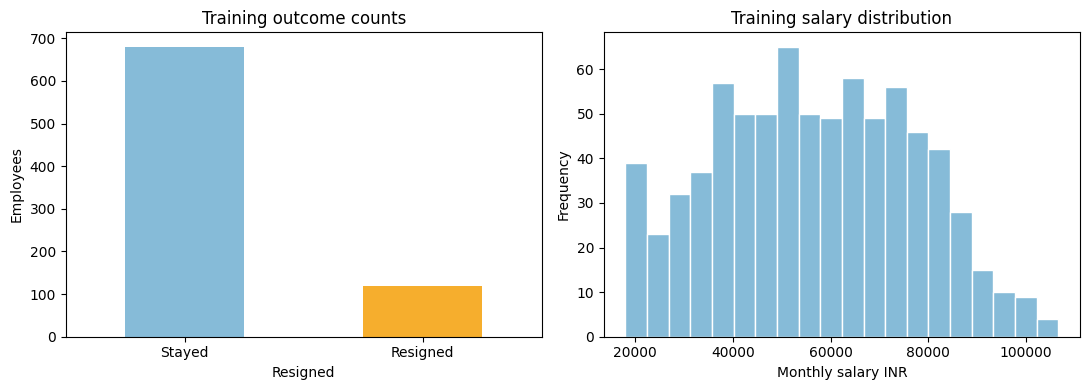

Resigned share in training data: 15.0 %


In [ ]:
# Display actual counts so students do not have to infer them from a chart.
counts = y_train.value_counts().sort_index()
display(counts.rename(index={0:'Stayed', 1:'Resigned'}).rename('Training count').to_frame())
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
counts.rename(index={0:'Stayed', 1:'Resigned'}).plot.bar(ax=axes[0], color=['#86BBD8','#F6AE2D'], rot=0)
axes[0].set(title='Training outcome counts', ylabel='Employees')
X_train['MonthlySalary'].plot.hist(bins=20, ax=axes[1], color='#86BBD8', edgecolor='white')
axes[1].set(title='Training salary distribution', xlabel='Monthly salary INR')
plt.tight_layout()
plt.show()
print('Resigned share in training data:', round(y_train.mean()*100, 1), '%')


## 11 EDA department patterns

**Purpose:** Compare observed training attrition rates by department. The generator did not deliberately make department cause attrition; small differences can arise by chance.


,count,AttritionPercent
Department,,
Finance,193,11.9
IT,181,15.5
Operations,183,20.8
Sales,217,13.8
NaN,26,3.8


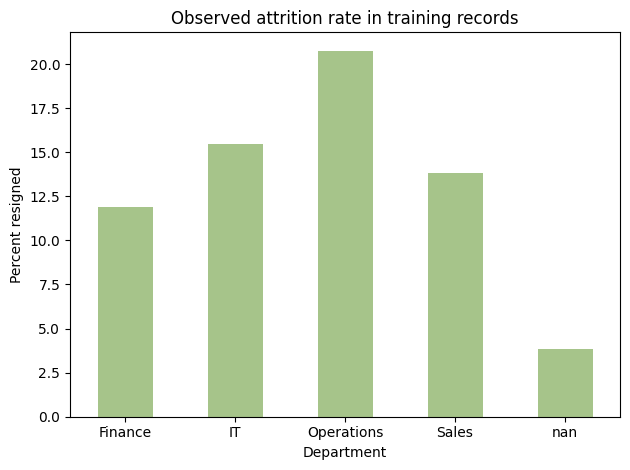

These associations do not establish causes or justify adverse HR decisions.


In [ ]:
# Group rates are averages of the 0/1 target, expressed as percentages.
rates = train_eda.groupby('Department', dropna=False)['Resigned'].agg(['count', 'mean'])
rates['AttritionPercent'] = rates['mean'] * 100
display(rates[['count', 'AttritionPercent']].round(1))
# Draw the rates of known departments.
rates['AttritionPercent'].plot.bar(color='#A6C48A', rot=0)
plt.title('Observed attrition rate in training records')
plt.ylabel('Percent resigned')
plt.tight_layout()
plt.show()
print('These associations do not establish causes or justify adverse HR decisions.')


## 12 Fill missing numerical values

**Purpose:** Replace missing numbers with each column's training median. Median is the middle value and is less sensitive to extreme values than the mean. Never learn replacements from the test set.


In [ ]:
# Fit learns medians from training data; transform applies those same medians.
num_imputer = SimpleImputer(strategy='median')
train_num = pd.DataFrame(num_imputer.fit_transform(X_train[numeric]), columns=numeric, index=X_train.index)
test_num = pd.DataFrame(num_imputer.transform(X_test[numeric]), columns=numeric, index=X_test.index)
display(pd.Series(num_imputer.statistics_, index=numeric, name='Training median').to_frame())
print('Missing training numbers remaining:', train_num.isna().sum().sum())


,Training median
ExperienceYears,12.0
MonthlySalary,55954.0
SatisfactionScore,3.0
OvertimeHours,17.0
Absences,6.0


Missing training numbers remaining: 0


## 13 Fill missing categories

**Purpose:** Replace missing department names with the most frequent training category for this teaching exercise. In real data, first investigate why values are missing; a Missing category may be more appropriate.


In [ ]:
# Learn the most frequent categories only from training records.
cat_imputer = SimpleImputer(strategy='most_frequent')
train_cat = pd.DataFrame(cat_imputer.fit_transform(X_train[categorical]), columns=categorical, index=X_train.index)
test_cat = pd.DataFrame(cat_imputer.transform(X_test[categorical]), columns=categorical, index=X_test.index)
display(pd.Series(cat_imputer.statistics_, index=categorical, name='Training replacement').to_frame())
print('Missing training categories remaining:', train_cat.isna().sum().sum())


,Training replacement
Department,Sales
WorkMode,Hybrid


Missing training categories remaining: 0


## 14 Scale numerical inputs

**Purpose:** Bring salary and smaller-valued inputs to comparable scales. StandardScaler uses training means and standard deviations. This matters for neighbour-based SMOTE and Logistic Regression.


In [ ]:
# Fit scaling on training numbers; apply the same scaling to test numbers.
scaler = StandardScaler()
train_scaled = pd.DataFrame(scaler.fit_transform(train_num), columns=numeric, index=X_train.index)
test_scaled = pd.DataFrame(scaler.transform(test_num), columns=numeric, index=X_test.index)
# Negative scaled values simply mean below the training average.
train_ready = pd.concat([train_scaled, train_cat], axis=1)
test_ready = pd.concat([test_scaled, test_cat], axis=1)
display(train_ready.head())
print('Categories remain names at this stage for categorical-aware oversampling.')


,ExperienceYears,MonthlySalary,SatisfactionScore,OvertimeHours,Absences,Department,WorkMode
385,-1.270321,-1.819928,1.470868,-0.017095,-1.347291,IT,Remote
538,0.199223,0.527395,1.470868,-1.061792,0.306672,Finance,Office
641,1.401578,0.809538,-0.010182,-1.441682,-0.244649,Operations,Hybrid
662,-1.671106,-1.725346,1.470868,0.837657,-0.520309,Operations,Remote
44,-1.537511,-1.554758,-1.491233,-0.776875,1.133654,Finance,Hybrid


Categories remain names at this stage for categorical-aware oversampling.


## 15 Apply SMOTE for mixed data using SMOTENC

**Purpose:** SMOTE creates artificial minority training examples using nearby records. Because this dataset contains numbers and categories, use SMOTENC, its mixed-data variant. Categories must not be interpolated into fractional departments. The test set is NEVER balanced.


In [ ]:
# Identify which columns contain categories rather than continuous numbers.
smote = SMOTENC(categorical_features=categorical, random_state=SEED, k_neighbors=5)
# Resample TRAINING inputs and labels only; test inputs remain untouched.
X_balanced, y_balanced = smote.fit_resample(train_ready, y_train)
# Print counts to show the actual effect of oversampling.
balance_table = pd.DataFrame({'Before': y_train.value_counts(), 'After': pd.Series(y_balanced).value_counts()}).sort_index()
balance_table.index = ['Stayed (0)', 'Resigned (1)']
display(balance_table)
print('Balanced rows are training examples, not newly observed employees.')


,Before,After
Stayed (0),680,680
Resigned (1),120,680


Balanced rows are training examples, not newly observed employees.


**SMOTE limitations:** It does not create new evidence, fix biased labels or guarantee better performance. Generated numerical values may be fractional, including values originally recorded as counts. Treat them as modelling representations. Real projects should compare alternatives using training-only validation. Probabilities from an oversampled classifier may require calibration before operational use.

Reference: [imbalanced-learn SMOTENC documentation](https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.SMOTENC.html).


## 16 Encode categories for the classifier

**Purpose:** One-hot encoding creates separate 0/1 columns for categories, avoiding an invented ranking between departments. Learn category names from original training records; reuse the encoder everywhere.


In [ ]:
# Learn training categories; ignore unseen categories safely during prediction.
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
encoder.fit(train_ready[categorical])
def make_model_inputs(table):
    # Encode categories and place numerical columns beside the encoded columns.
    category_values = encoder.transform(table[categorical])
    return np.hstack([table[numeric].to_numpy(dtype=float), category_values])
# Prepare original training data, balanced training data and untouched test data.
X_train_model = make_model_inputs(train_ready)
X_balanced_model = make_model_inputs(X_balanced)
X_test_model = make_model_inputs(test_ready)
feature_names = numeric + encoder.get_feature_names_out(categorical).tolist()
print('Classifier columns:', feature_names)
print('Balanced input shape:', X_balanced_model.shape)


Classifier columns: ['ExperienceYears', 'MonthlySalary', 'SatisfactionScore', 'OvertimeHours', 'Absences', 'Department_Finance', 'Department_IT', 'Department_Operations', 'Department_Sales', 'WorkMode_Hybrid', 'WorkMode_Office', 'WorkMode_Remote']
Balanced input shape: (1360, 12)


## 17 Train a baseline without SMOTE

**Purpose:** A comparison is needed to judge the effect of oversampling. Logistic Regression predicts a category despite its name. No class weighting is added, so the comparison isolates SMOTENC.


In [ ]:
# Train on the original, imbalanced training examples.
baseline = LogisticRegression(max_iter=1000, random_state=SEED)
baseline.fit(X_train_model, y_train)
print('Baseline trained without oversampling.')


Baseline trained without oversampling.


## 18 Train the SMOTENC model

**Purpose:** Train the same algorithm using the balanced training examples. Only the training data differs from the baseline.


In [ ]:
# Train a second model on the artificial-plus-original training examples.
balanced_model = LogisticRegression(max_iter=1000, random_state=SEED)
balanced_model.fit(X_balanced_model, y_balanced)
print('SMOTENC model trained. Both models will use the same test set.')


SMOTENC model trained. Both models will use the same test set.


## 19 Evaluate both models

**Purpose:** Report accuracy, precision, recall and F1 on the same held-out employees. Use default threshold 0.5. This is a teaching comparison; choose or tune a production model using separate validation or cross-validation, not repeated test inspection.


In [ ]:
# Generate predictions without fitting anything on the test set.
pred_baseline = baseline.predict(X_test_model)
pred_balanced = balanced_model.predict(X_test_model)
def metric_row(name, predictions):
    # zero_division avoids a warning if a model predicts no positive cases.
    return {'Model': name, 'Accuracy': accuracy_score(y_test, predictions),
            'Precision': precision_score(y_test, predictions, zero_division=0),
            'Recall': recall_score(y_test, predictions, zero_division=0),
            'F1': f1_score(y_test, predictions, zero_division=0)}
results = pd.DataFrame([metric_row('Without SMOTE', pred_baseline), metric_row('With SMOTENC', pred_balanced)]).set_index('Model')
display((results * 100).round(2).rename(columns=lambda x: x+' %'))
print('No result is guaranteed to improve. Use the actual printed scores.')


,Accuracy %,Precision %,Recall %,F1 %
Model,,,,
Without SMOTE,83.0,30.0,10.0,15.00
With SMOTENC,67.0,25.0,60.0,35.29


No result is guaranteed to improve. Use the actual printed scores.


## 20 Read the confusion matrices

**Purpose:** See missed resignations (FN) and unnecessary flags (FP), rather than relying on one score. Rows show actual outcomes; columns show predictions.


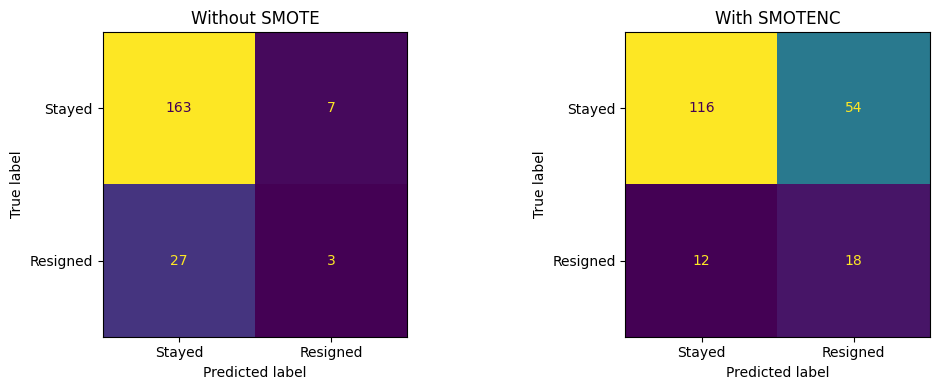

SMOTENC model: TN=116, FP=54, FN=12, TP=18
Missed resignations: 12; unnecessary flags: 54.
              precision    recall  f1-score   support

      Stayed       0.91      0.68      0.78       170
    Resigned       0.25      0.60      0.35        30

    accuracy                           0.67       200
   macro avg       0.58      0.64      0.57       200
weighted avg       0.81      0.67      0.71       200



In [ ]:
# Plot both models with the same labels and orientation.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name, predictions in zip(axes, ['Without SMOTE', 'With SMOTENC'], [pred_baseline, pred_balanced]):
    ConfusionMatrixDisplay.from_predictions(y_test, predictions, labels=[0,1], display_labels=['Stayed','Resigned'], ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()
# Flatten in row order: TN, FP, FN, TP.
tn, fp, fn, tp = confusion_matrix(y_test, pred_balanced, labels=[0,1]).ravel()
print(f'SMOTENC model: TN={tn}, FP={fp}, FN={fn}, TP={tp}')
print(f'Missed resignations: {fn}; unnecessary flags: {fp}.')
print(classification_report(y_test, pred_balanced, target_names=['Stayed','Resigned'], zero_division=0))


## 20A Classification report: connect the code to our metrics theory

### The report image from this notebook
The image below renders the actual saved text output from Step 20. It is a report output image, not a screenshot of the Colab interface. These are this notebook's saved results, not invented sample scores. Rerunning changed data or settings can change the results.

![Actual saved classification report](attachment:Monday_Classification_Report.png)

### 1. What is being evaluated?
Logistic Regression is a **classification algorithm** here: it predicts one of two categories. `Resigned` is the target, **0 = Stayed; 1 = Resigned**. Positive means the class we want to detect, not something good. This is the same idea used in our theory examples: define the positive class first.

`y_test` contains the known outcomes of 200 held-out historical employees. `pred_balanced` contains predictions from the model trained with SMOTENC. `classification_report(y_test, pred_balanced, ...)` compares actual outcomes with predictions. The test records are never balanced with SMOTE. Support counts the original test outcomes, not synthetic training examples.

### 2. Start with the confusion matrix
Rows = actual outcomes; columns = predicted outcomes. Keep class 1 (Resigned) as positive for TP/TN/FP/FN.

| Actual / Predicted | Stayed (0) | Resigned (1) | Actual total |
|---|---:|---:|---:|
| Stayed (0) | TN = 116 | FP = 54 | 170 |
| Resigned (1) | FN = 12 | TP = 18 | 30 |
| Predicted total | 128 | 72 | 200 |

**TN 116:** The employee stayed and the model predicted Stayed: correct.

**FP 54:** The employee stayed but the model predicted Resigned: a false retention alert.

**FN 12:** The employee resigned but the model predicted Stayed: a missed resignation.

**TP 18:** The employee resigned and the model predicted Resigned: correct detection.

Checkpoint: 116 + 54 + 12 + 18 = 200. Correct = 116 + 18 = 134; incorrect = 54 + 12 = 66. Actual resigned = 18 + 12 = 30; flagged resigned = 18 + 54 = 72.

### 3. Read the Resigned row: these are the positive-class theory metrics

| Metric | Theory question | Calculation using this output | Report value |
|---|---|---|---|
| Precision | Of employees flagged as Resigned, how many actually resigned? | TP / (TP + FP) = 18 / 72 = 25% | 0.25 |
| Recall | Of employees who actually resigned, how many did we identify? | TP / (TP + FN) = 18 / 30 = 60% | 0.60 |
| F1-score | How well are precision and recall balanced? | 2TP / (2TP + FP + FN) = 36 / 102 = 35.29% | 0.35 |
| Support | How many actually belonged to this class in the test set? | TP + FN = 18 + 12 = 30 | 30 |

**Precision and recall use different denominators.** Precision starts with 72 model alerts. Recall starts with 30 actual resignations. That is why 25% and 60% can both be correct.

In HR language: only 18 of 72 alerts matched actual resignations; 54 alerts were false positives. The model caught 18 of 30 actual resignations but missed 12 (40%). F1 is the harmonic mean, not the simple average: 2 × 0.25 × 0.60 / (0.25 + 0.60) = 0.3529. The ordinary average would be 0.425 and is not the F1-score.

### 4. Read the Stayed row: each class gets its own precision and recall
Scikit-learn evaluates each row by temporarily treating that row's class as the class of interest. The confusion matrix labels above still refer to Resigned as positive; use these formulas to read the Stayed row.

| Metric for Stayed | Calculation | Interpretation |
|---|---|---|
| Precision | TN / (TN + FN) = 116 / 128 = 90.625% → 0.91 | Of 128 predictions of Stayed, 116 actually stayed |
| Recall | TN / (TN + FP) = 116 / 170 = 68.235% → 0.68 | Of 170 actual stayers, 116 were identified as Stayed |
| F1 | 2TN / (2TN + FN + FP) = 232 / 298 = 77.852% → 0.78 | Harmonic mean of Stayed precision and recall |
| Support | TN + FP = 170 | 170 employees actually stayed |

Stayed recall is also called **specificity** when Resigned is the positive class. The Stayed precision of 0.91 does not mean the model detects 91% of resignations. Always name the row when interpreting a number.

### 5. Accuracy: connect to the formula learned in theory
Accuracy = (TP + TN) / total = (18 + 116) / 200 = **67%**, printed as 0.67. It describes overall correctness across both classes. It is not 67% precision or 67% recall for Resigned. The blank precision/recall columns on the accuracy line are normal: accuracy is one overall score.

This test set has 170 stayers and 30 resignations. A rule predicting Stayed for everyone would obtain 170 / 200 = **85% accuracy**, but 0% Resigned recall. The SMOTENC model has lower accuracy (67%) and catches 60% of resignations. Neither score alone identifies a suitable HR model. Compare both actual model outputs and error costs.

### 6. Macro average: give each class equal importance
Macro means the ordinary average of the two **unrounded class scores**; support does not affect the weights.

Macro precision = (0.90625 + 0.25) / 2 = 0.578125 → **0.58**.

Macro recall = (0.68235294 + 0.60) / 2 = 0.64117647 → **0.64**.

Macro F1 = (0.77852349 + 0.35294118) / 2 = 0.56573233 → **0.57**.

Macro F1 is the average of the class F1 scores. Do not calculate it by taking the harmonic mean of macro precision and macro recall. Both classes count equally even though there are many more stayers.

### 7. Weighted average: weight by actual support
The class weights are 170 / 200 = 0.85 for Stayed and 30 / 200 = 0.15 for Resigned.

Weighted precision = (170 × 0.90625 + 30 × 0.25) / 200 = 0.8078125 → **0.81**.

Weighted recall = (170 × 0.68235294 + 30 × 0.60) / 200 = 0.67 → **0.67**.

Weighted F1 = (170 × 0.77852349 + 30 × 0.35294118) / 200 = 0.71468614 → **0.71**.

Weighted precision of 0.81 does not mean 81% of resignation alerts are correct: that is the Resigned precision of 0.25. The majority Stayed class dominates the weighted score. In this ordinary single-label classification report, weighted recall equals accuracy. Weighted F1 need not equal accuracy. Support 200 on the average lines is total test support, not 200 in each class.

### 8. Decimals, percentages and rounding
0.25 = 25%; 0.60 = 60%; 0.35 is a rounded display of approximately 35.29%. Scores are proportions, while support is a count. The report defaults to two decimal places. Calculate averages from full-precision values or counts; averaging the displayed rounded numbers can produce a small mismatch.

### 9. Turn the metrics into a business discussion
If HR wants to miss fewer resignations, focus on Resigned recall and FN. If HR has limited time for follow-up and wants fewer false alerts, focus on Resigned precision and FP. Review both together using F1 and the confusion matrix. Here, 54 false alerts make a blanket claim of strong performance inappropriate. Supportive conversations require human judgment; a prediction is not proof that an employee intends to leave.

A suitable student statement is: “On 200 synthetic test employees, the SMOTENC Logistic Regression model correctly classified 134 (67%). It identified 18 of 30 resignations (60% recall), but only 18 of 72 resignation alerts were correct (25% precision). Its Resigned F1-score was 35.29%. We would investigate the 12 missed resignations and 54 false alerts and use separate validation before selecting a retention model.”

### 10. Check your understanding
1. Why is Resigned support 30, not 72? **30 is actual resignations; 72 is predicted resignation alerts.**
2. Which number is the denominator of precision? **72 = TP + FP.**
3. Which number is the denominator of recall? **30 = TP + FN.**
4. Does weighted precision 0.81 describe resignation alerts? **No; use the Resigned row's 0.25.**
5. How many cases were correct? **134 = TP + TN.**
6. Why can 85% accuracy still miss every resignation? **Predicting the majority Stayed class for all employees gives zero positive recall.**

### 20B Recalculate the explanations from your current run
The next code cell uses your current `y_test` and `pred_balanced`. Its explanations and image update automatically when predictions change; the saved report image above remains a labelled reference to the original run.


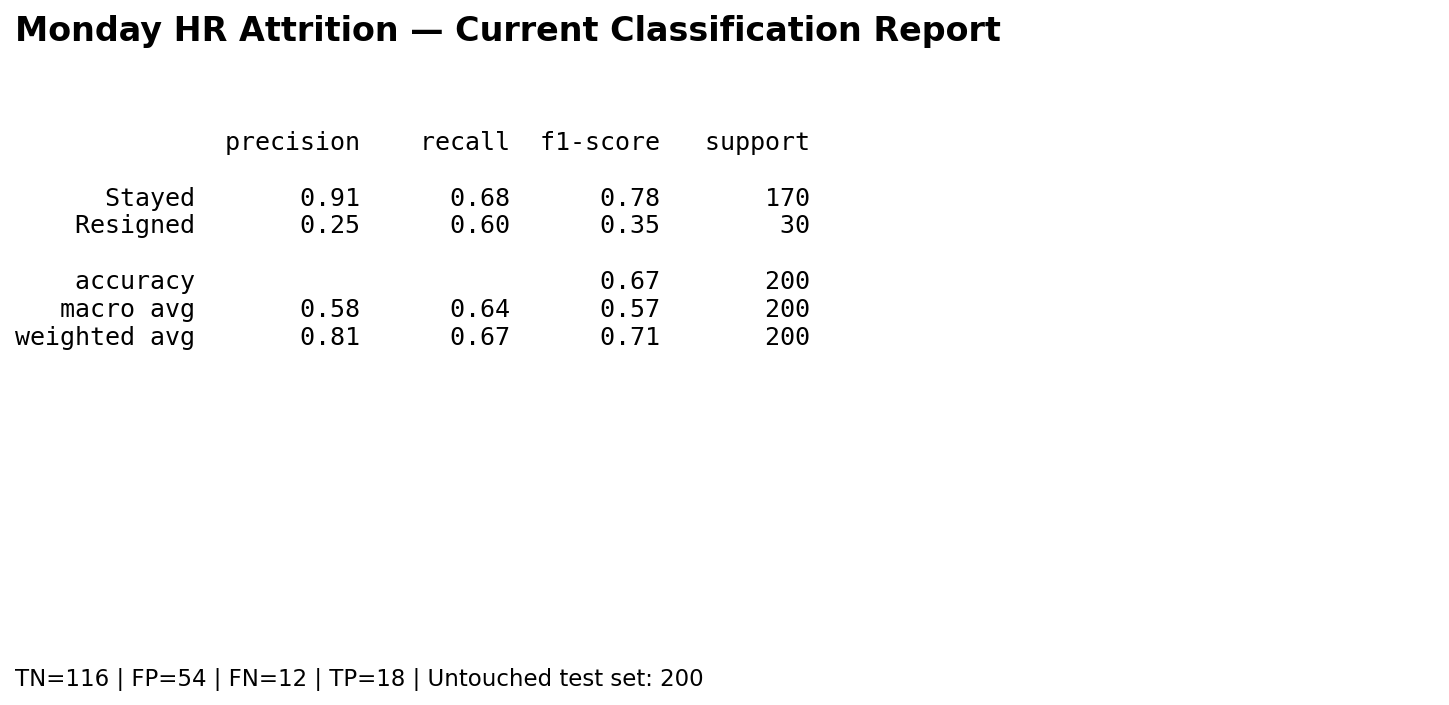

In [ ]:
# Recreate the theory calculations from the CURRENT test predictions.
# labels=[0,1] fixes the order: Stayed first, Resigned second.
tn_now, fp_now, fn_now, tp_now = confusion_matrix(y_test, pred_balanced, labels=[0, 1]).ravel()
# Avoid division by zero if a future run contains no predicted positives.
def safe_divide(numerator, denominator):
    return numerator / denominator if denominator else 0.0
# Use raw counts rather than rounded classification-report values.
print(f"TN={tn_now}, FP={fp_now}, FN={fn_now}, TP={tp_now}")
print(f"Accuracy: ({tn_now}+{tp_now})/{len(y_test)} = {(tn_now+tp_now)/len(y_test):.2%}")
print(f"Resigned precision: {tp_now}/({tp_now}+{fp_now}) = {safe_divide(tp_now,tp_now+fp_now):.2%}")
print(f"Resigned recall: {tp_now}/({tp_now}+{fn_now}) = {safe_divide(tp_now,tp_now+fn_now):.2%}")
print(f"Resigned F1: {2*tp_now}/({2*tp_now}+{fp_now}+{fn_now}) = {safe_divide(2*tp_now,2*tp_now+fp_now+fn_now):.2%}")
print(f"Of {tp_now+fp_now} resignation alerts, {tp_now} were correct and {fp_now} were false alerts.")
print(f"Of {tp_now+fn_now} actual resignations, {tp_now} were detected and {fn_now} were missed.")
# Generate the report text and save an output image for the student's presentation.
current_report = classification_report(y_test, pred_balanced, labels=[0,1], target_names=['Stayed','Resigned'], zero_division=0)
fig = plt.figure(figsize=(11, 5))
fig.text(0.04, 0.92, 'Monday HR Attrition — Current Classification Report', fontsize=16, weight='bold')
fig.text(0.04, 0.80, current_report, fontsize=12, family='monospace', va='top')
fig.text(0.04, 0.06, f'TN={tn_now} | FP={fp_now} | FN={fn_now} | TP={tp_now} | Untouched test set: {len(y_test)}', fontsize=11)
plt.axis('off')
plt.savefig('Monday_Classification_Report_Current.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved image: Monday_Classification_Report_Current.png (Colab Files panel).')


## 21 Explain the result in business language

**Purpose:** Convert outputs into a cautious HR recommendation. Model coefficients describe fitted associations, not causes. The lab is not a validated HR deployment.


In [ ]:
# Report the observed change rather than assuming SMOTE helped.
recall_change = 100 * (results.loc['With SMOTENC','Recall'] - results.loc['Without SMOTE','Recall'])
print(f'Test recall changed by {recall_change:+.2f} percentage points after SMOTENC.')
print(f'The SMOTENC model missed {fn} actual resignations and incorrectly flagged {fp} employees.')
print('Recommendation: investigate supportive interventions and evaluate costs before use.')
print('Do not use these synthetic-data results for hiring, promotion or termination decisions.')
# Show associations within the fitted model, including encoded categories.
coefficients = pd.Series(balanced_model.coef_[0], index=feature_names).sort_values()
display(coefficients.rename('Fitted coefficient').to_frame())
print('Positive coefficients raise fitted log-odds holding other inputs fixed; they do not prove causation.')


Test recall changed by +50.00 percentage points after SMOTENC.
The SMOTENC model missed 12 actual resignations and incorrectly flagged 54 employees.
Recommendation: investigate supportive interventions and evaluate costs before use.
Do not use these synthetic-data results for hiring, promotion or termination decisions.


,Fitted coefficient
SatisfactionScore,-1.046605
MonthlySalary,-0.546552
WorkMode_Hybrid,-0.540634
Department_Sales,-0.217997
Department_Finance,-0.217774
WorkMode_Office,-0.067977
Department_IT,-0.065878
ExperienceYears,0.120132
OvertimeHours,0.389536
Absences,0.433248


Positive coefficients raise fitted log-odds holding other inputs fixed; they do not prove causation.


## 22 Predict a new fictional employee

**Purpose:** Reuse fitted imputers, scaler, encoder and classifier. Never refit them on a new employee. The score is a model output, not a calibrated certainty about a person.


In [ ]:
# Build one fictional input with the same columns as training data.
new_employee = pd.DataFrame([{'ExperienceYears':3, 'MonthlySalary':35000,
    'SatisfactionScore':2, 'OvertimeHours':28, 'Absences':8,
    'Department':'Sales', 'WorkMode':'Hybrid'}])
# Reuse the training medians, category replacements and scaling parameters.
new_num = scaler.transform(num_imputer.transform(new_employee[numeric]))
new_cat = cat_imputer.transform(new_employee[categorical])
new_ready = pd.concat([pd.DataFrame(new_num, columns=numeric), pd.DataFrame(new_cat, columns=categorical)], axis=1)
new_model_inputs = make_model_inputs(new_ready)
new_prediction = balanced_model.predict(new_model_inputs)[0]
new_score = balanced_model.predict_proba(new_model_inputs)[0,1]
print('Predicted class:', 'Resigned (1)' if new_prediction == 1 else 'Stayed (0)')
print('Uncalibrated model score:', round(float(new_score), 3))
print('This is a synthetic demonstration; a human must review any real-world use.')


Predicted class: Resigned (1)
Uncalibrated model score: 0.624
This is a synthetic demonstration; a human must review any real-world use.


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


## 23 Save outputs and reusable model components

**Purpose:** Save the complete preprocessing recipe, classifier and results. Saving only the classifier would make future inputs inconsistent. Files appear in Colab's left Files panel.


In [ ]:
# Store all fitted objects needed to recreate a prediction.
bundle = {'numeric_columns':numeric, 'categorical_columns':categorical,
          'numeric_imputer':num_imputer, 'category_imputer':cat_imputer,
          'scaler':scaler, 'encoder':encoder, 'model':balanced_model,
          'seed':SEED, 'target':'Resigned', 'positive_class':1}
joblib.dump(bundle, 'hr_attrition_teaching_model.joblib')
results.to_csv('model_comparison.csv')
clean.to_csv('hr_attrition_cleaned.csv', index=False)
# Verify evaluation data stayed unchanged and categories remained valid during SMOTE.
assert X_test.equals(test_snapshot)
for column in categorical:
    assert set(X_balanced[column]) <= set(train_ready[column])
print('Saved: hr_attrition_teaching_model.joblib, model_comparison.csv, hr_attrition_cleaned.csv')
print('Verified: raw test inputs unchanged; synthetic categories valid.')
print('Only load joblib files you trust, because deserialisation can execute code.')


Saved: hr_attrition_teaching_model.joblib, model_comparison.csv, hr_attrition_cleaned.csv
Verified: raw test inputs unchanged; synthetic categories valid.
Only load joblib files you trust, because deserialisation can execute code.


## Student practice and submission
1. Explain the missing-value replacements and why they came from training data.
2. Record both models' actual four metrics. Which increased and which decreased?
3. Explain FP and FN using the printed numbers.
4. Why is EmployeeID excluded? Why would exit-interview information leak the answer?
5. Explain why oversampling test data would invalidate evaluation.
6. Describe one limitation of the synthetic dataset and one fairness concern.
7. Submit this executed notebook with a five-sentence findings paragraph. Keep all outputs visible.

**Optional extension after the core lab:** Add training-only cross-validation using an imbalanced-learn Pipeline that refits preprocessing and SMOTENC inside every fold. Do not run cross-validation on data oversampled before the folds are created.

**Suggested three-hour pacing:** introduction/setup 20 min; loading/cleaning 25; split/EDA 30; preprocessing 35; SMOTENC/training 30; evaluation/interpretation 25; submission/interview review 15.


## Interview questions with answer hints
1. **What business problem did you solve?** A synthetic attrition prediction exercise for supportive HR review.
2. **What are features and a target?** Features are inputs; Resigned is the known historical outcome.
3. **Why is this classification?** The output is one of two classes, rather than a numerical quantity.
4. **Why remove duplicates before splitting?** The same record in train and test would inflate performance.
5. **Why split before imputation and scaling?** Test information must not influence fitted preprocessing.
6. **Why median imputation?** It supplies a robust middle value for this exercise; the missingness mechanism still needs investigation in real data.
7. **Why one-hot encoding?** Departments have no natural numerical ranking.
8. **Why scale inputs?** Salary otherwise dominates neighbour distances; scaling also supports optimisation.
9. **What is class imbalance?** One target class has substantially more examples.
10. **What does SMOTE do?** Creates artificial minority training examples from neighbourhoods.
11. **Why SMOTENC?** This dataset combines continuous and categorical features.
12. **Why not balance the test set?** Evaluation should reflect the untouched held-out distribution.
13. **Can SMOTE guarantee improvement?** No; compare actual held-out metrics and validation results.
14. **Why is Logistic Regression a classifier?** It models a class score and maps that score to a category.
15. **Precision versus recall?** Precision concerns genuine positives among flags; recall concerns positives caught among actual positives.
16. **Which error is FN here?** An employee who resigned but was predicted to stay.
17. **Does high accuracy prove fairness?** No; assess group outcomes, data bias and consequences separately.
18. **Can coefficients prove why employees leave?** No; fitted predictive associations are not causal evidence.
19. **Can the model score be treated as a reliable probability after SMOTE?** Not automatically; assess calibration on representative validation data.
20. **What would you improve before production?** Representative data, time-aware evaluation, validation/CV, calibration, fairness assessment, governance and ongoing monitoring.


## GitHub README
Copy the following content into your repository's `README.md`. Replace the results placeholder with your observed scores.

# HR Attrition ML Pipeline

An educational classification project using automatically generated synthetic employee records. The goal is to demonstrate a complete, understandable machine-learning workflow for HR attrition prediction.

## Business objective
Identify possible future resignations to illustrate supportive retention review. This project does not establish causes of attrition and is not suitable for operational employee decisions.

## Dataset
1,000 fictional employee records, plus 20 deliberately duplicated rows before cleaning. Inputs include experience, salary, satisfaction, overtime, absences, department and work mode. Missing values are deliberately introduced. Target: 0 = stayed, 1 = resigned within the following year. No real employee data is used.

## ML pipeline step by step
1. **Loading:** Generate fictional records, save a CSV and load it with Pandas.
2. **Inspection:** Examine shape, data types, missing values and repeated rows.
3. **Cleaning:** Remove exact duplicates and validate basic target and feature ranges.
4. **Feature selection:** Exclude identifiers and keep only information available at prediction time.
5. **Splitting:** Use an 80/20 stratified training/test split before fitting preprocessing.
6. **EDA:** Summarise and visualise training data; examine imbalance and descriptive patterns.
7. **Imputation:** Learn numerical medians and categorical modes on training data.
8. **Scaling:** Fit StandardScaler on training numbers and reuse it for other inputs.
9. **SMOTE:** Apply SMOTENC only to training data because inputs contain numbers and categories.
10. **Encoding:** Learn one-hot categories from original training data and transform each model input.
11. **Training:** Fit Logistic Regression with and without oversampling.
12. **Evaluation:** Compare accuracy, precision, recall, F1 and confusion matrices on the same untouched test set.
13. **Interpretation:** Describe missed resignations, false flags, limitations and human review.
14. **Prediction:** Reuse every fitted preprocessing component for a new fictional employee.
15. **Saving:** Export results, cleaned data and fitted preprocessing/model components.

## Tools
Python, Pandas, NumPy, Matplotlib, Scikit-learn, imbalanced-learn, Joblib and Google Colab.

## Results
Insert the actual baseline and SMOTENC results from the notebook. Report tradeoffs honestly; do not assume that oversampling improved every metric.

## Running the project
Open the notebook in Google Colab, use a CPU runtime and run all cells from top to bottom. The setup cell installs the specified package versions. The dataset is created automatically.

## Files
- HR_Attrition_Monday_Complete_Pipeline.ipynb — guided notebook
- hr_attrition_raw.csv — generated teaching data
- hr_attrition_cleaned.csv — deduplicated data; fitted imputation remains training-only
- model_comparison.csv — observed evaluation scores
- hr_attrition_teaching_model.joblib — fitted preprocessing components and classifier

## Limitations and responsible use
Synthetic data cannot demonstrate real-world effectiveness. Oversampling creates examples rather than evidence; scores can need calibration. Group associations and coefficients do not show causation. Evaluation here is a teaching comparison, not production model selection. Real deployment requires representative data, validation, privacy controls, fairness review, human oversight and monitoring. Load saved models only from trusted sources.

## Learning outcomes
Data loading, cleaning, EDA, leakage-aware preprocessing, imbalance handling, classification, evaluation and business interpretation.
